# Evaluation
## 1. Setup

In [24]:
pip install rouge-score


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [25]:
import re, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.metrics import f1_score, cohen_kappa_score, recall_score

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
WAD_ROOT = Path("/Users/amynguyen/Documents/MQ/(26_2) FOSE7902 - Advanced STEM Research Placement/WAD/wad_dataset_v2")  # WAD text, part 4.3 only
SUBSET = "test"
PROMPT_VERSION = "v13"
SUBSETS = ["dev_00", "check_01", "check_02", "check_03", "check_04", "test"]
N_BOOT, SEED = 2000, 42

OUT = REPO_ROOT / "results" / "outputs"
TABLES = REPO_ROOT / "results" / "tables"
FIGS = REPO_ROOT / "results" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)

ACTIONS = ["continue", "slow", "move", "stop"] # ordered by urgency
LEVELS = ["stop", "move", "slow", "caution", "clear"] # the module's decision levels
LEVEL_TO_ACTION = {"stop": "stop", "move": "move", "slow": "slow", "caution": "continue", "clear": "continue"}
OURS, OTHER, INK = "#2a78d6", "#a8a8a3", "#222222"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

sys.path.insert(0, str(REPO_ROOT / "scripts"))
from wad_parser import parse

In [26]:
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300, "font.size": 8,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY_D, GREY_L = "#0072B2", "#D55E00", "#8C96A3", "#C9CED6"   # colour-blind safe

### Load all sources

In [27]:
def cats(x):
    return set() if pd.isna(x) or x == "" else set(str(x).split("|"))

def wad(subset=SUBSET):
    """WAD's reminders, read by the parser (data/references)."""
    r = REFS[REFS.subset == subset]
    return pd.DataFrame({"top": r.primary_hazard, "hazards": r.hazards.map(cats), "clock": r.primary_clock,
                         "action": r.action, "clear": r.path_clear.astype(bool), "silent": r.path_clear.astype(bool)})

def module(subset=SUBSET, variant=None):
    """The module's hint: top hazard, top 3, direction and decision (a variant = an ablation)."""
    d = OUT / subset
    hints = pd.read_json(d / (f"ablations/{variant}_hints.jsonl" if variant else "hints.jsonl"), lines=True).set_index("clip_id")
    rank = pd.read_parquet(d / (f"ablations/{variant}_ranking.parquet" if variant else "ranking.parquet"))
    top3 = rank[rank["rank"] <= 3].groupby("clip_id").category.apply(set).reindex(hints.index)
    clear = hints.level.eq("clear")
    return pd.DataFrame({"top": hints.top_category, "hazards": [set() if c or not isinstance(t, set) else t for c, t in zip(clear, top3)],
                         "clock": hints.top_clock, "action": hints.level.map(LEVEL_TO_ACTION), "clear": clear,
                         "silent": clear, "level": hints.level})

def baseline(name, subset=SUBSET):
    """A simple rule (nearest, largest, most confident, random object); never says clear."""
    b = pd.read_parquet(OUT / subset / "baselines.parquet")
    b = b[b.baseline == name].set_index("clip_id")
    return pd.DataFrame({"top": b.top_category, "hazards": b.top_category.map(lambda t: {t} if isinstance(t, str) else set()),
                         "clock": b.top_clock, "action": np.nan, "clear": b.clear.astype(bool), "silent": b.clear.astype(bool)})

def qwen(condition):
    """Qwen's replies, read by the same parser as WAD."""
    p = pd.DataFrame([parse(t) for t in QWEN[f"qwen_{condition}"]], index=QWEN.index)
    hz = p.hazards.map(cats)
    return pd.DataFrame({"top": p.primary_hazard, "hazards": hz, "clock": p.primary_clock, "action": p.action,
                         "clear": p.path_clear, "silent": p.action.eq("continue") & hz.map(len).eq(0)})

def judge(j):
    """One judge's blind labels; 'none' = nothing in the way."""
    l = pd.read_csv(OUT / "human" / f"blind_labels_judge{j}.csv").set_index("frame_path")
    none = l.hazard.eq("none")
    return pd.DataFrame({"top": l.hazard.where(~none), "hazards": [set() if n else {h} for n, h in zip(none, l.hazard)],
                         "clock": pd.to_numeric(l.clock), "action": l.action, "clear": none, "silent": none})

REFS = pd.read_csv(REPO_ROOT / "data" / "references" / "wad_references.csv").set_index("frame_path")
QWEN = pd.read_json(OUT / "qwen" / f"qwen_full_{PROMPT_VERSION}.jsonl", lines=True).set_index("clip_id")
WAD, MODULE = wad(), module()
HINT = pd.read_json(OUT / SUBSET / "hints.jsonl", lines=True).set_index("clip_id")["hint"]
J1, J2 = judge(1), judge(2)
JUDGES = pd.concat([J1, J2.drop(J1.index, errors="ignore")]) # 350 clips, shared clips once (judge 1)
QW = {c: qwen(c) for c in ["none", "list", "ranked"]}
print(f"{SUBSET}: {len(WAD)} clips | Qwen {len(QWEN)} | judges {len(J1)} + {len(J2)} ({len(J1.index.intersection(J2.index))} shared)")

test: 1007 clips | Qwen 1007 | judges 200 + 200 (50 shared)


### Scoring helpers

In [28]:
def clock_ok(a, b):
    d = abs(a - b) % 12
    return np.where(np.isnan(d), np.nan, (np.minimum(d, 12 - d) <= 1).astype(float))

def per_clip(pred, ref):
    idx = pred.index.intersection(ref.index)
    p, r = pred.loc[idx], ref.loc[idx]
    named = r.hazards.map(len) > 0
    top1 = np.where(named, [t in h for t, h in zip(p.top, r.hazards)], np.nan)
    top3 = np.where(named, [len(a & b) > 0 for a, b in zip(p.hazards, r.hazards)], np.nan)
    warns = r.action.ne("continue")
    return pd.DataFrame({"top-1": top1, "top-3": top3,
                         "direction": np.where(top1 == 1, clock_ok(p.clock.astype(float), r.clock.astype(float)), np.nan),
                         "clear agrees": (p.clear == r.clear).astype(float),
                         "action": np.where(p.action.isna(), np.nan, (p.action == r.action).astype(float)),
                         "silent": np.where(warns, p.silent.astype(float), np.nan)}, index=idx)

def ci(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    m = np.random.default_rng(SEED).choice(x, (N_BOOT, len(x))).mean(1)
    return x.mean(), np.percentile(m, 2.5), np.percentile(m, 97.5)

def summary(pc, measures=("top-1", "top-3", "direction", "clear agrees", "action", "silent")):
    return {m: "{:.0%} [{:.0%}, {:.0%}]".format(*ci(pc[m])) if pc[m].notna().any() else "–" for m in measures}

def kappa(pred, ref, weights=None):
    idx = pred.index.intersection(ref.index)
    return cohen_kappa_score(ref.action.loc[idx], pred.action.loc[idx], labels=ACTIONS, weights=weights)

def mcnemar(a, b):
    # a, b: per-clip 0/1 for two methods on the same clips -> a better / b better, p
    m = a.notna() & b.notna()
    win, loss = int(((a == 1) & (b == 0))[m].sum()), int(((a == 0) & (b == 1))[m].sum())
    return f"{win} / {loss}, p = {binomtest(win, max(win + loss, 1)).pvalue:.3f}"

def save_table(df, name):
    df.to_csv(TABLES / f"{name}.csv")
    return df

def save_fig(fig, name):
    fig.savefig(FIGS / f"{name}.png", dpi=200, bbox_inches="tight")

## 2. Reference labels

### 2.1. Parser accuracy (hand-checked reminders)

In [29]:
OK = ["ok_hazard", "ok_clock", "ok_action", "ok_clear"]
ref_dir = REPO_ROOT / "data" / "references"
save_table(pd.DataFrame({"round 1 (n=100)": pd.read_csv(ref_dir / "manual_check_dev_00.csv")[OK].mean(),
                         "round 2 (n=50)": pd.read_csv(ref_dir / "manual_check_dev_00_round2.csv")[OK].mean()}).round(2),
           "parser_accuracy")

,round 1 (n=100),round 2 (n=50)
ok_hazard,0.92,0.98
ok_clock,0.98,0.98
ok_action,0.91,1.00
ok_clear,1.00,1.00


### 2.2. Content of the WAD reminders

In [30]:
r = REFS[REFS.subset == SUBSET]
content = pd.Series({
    "action: continue": r.action.eq("continue").mean(), "action: slow": r.action.eq("slow").mean(),
    "action: move": r.action.eq("move").mean(), "action: stop": r.action.eq("stop").mean(),
    "names no hazard": r.n_hazards.eq(0).mean(), "names one hazard": r.n_hazards.eq(1).mean(),
    "names two or more": r.n_hazards.ge(2).mean(),
    "gives a direction": r.primary_clock.notna().mean(), "gives a distance": r.primary_dist_steps.notna().mean()},
    name=f"share of {len(r)} reminders").round(2)
save_table(content.to_frame(), "wad_content")

,share of 1007 reminders
action: continue,0.74
action: slow,0.14
action: move,0.10
action: stop,0.02
names no hazard,0.07
names one hazard,0.57
names two or more,0.36
gives a direction,0.86
gives a distance,0.12


### 2.3. Agreement between the judges

In [31]:
agree = pd.DataFrame({
    "judge 1 vs judge 2 (shared)": summary(per_clip(J1, J2), ["top-1", "direction", "clear agrees", "action"]),
    "WAD vs judges": summary(per_clip(WAD, JUDGES), ["top-1", "direction", "clear agrees", "action"])}).T
agree["action kappa"] = [f"{kappa(J1, J2):.2f}", f"{kappa(WAD, JUDGES):.2f}"]
save_table(agree, "reference_agreement")

,top-1,direction,clear agrees,action,action kappa
judge 1 vs judge 2 (shared),"84% [72%, 94%]","98% [93%, 100%]","96% [90%, 100%]","90% [82%, 98%]",0.85
WAD vs judges,"44% [39%, 49%]","90% [86%, 95%]","93% [90%, 95%]","36% [31%, 41%]",0.05


## 3. Module vs references 

### 3.1. Hazard and direction

In [32]:
rows = {"module vs WAD": summary(per_clip(MODULE, WAD), ["top-1", "top-3", "direction", "clear agrees"])}
for b in ["nearest", "largest", "most_confident", "random"]:
    rows[f"{b} object vs WAD"] = summary(per_clip(baseline(b), WAD), ["top-1", "direction", "clear agrees"])
rows["module vs judges"] = summary(per_clip(MODULE, JUDGES), ["top-1", "top-3", "direction", "clear agrees"])
rows["WAD vs judges"] = summary(per_clip(WAD, JUDGES), ["top-1", "top-3", "direction", "clear agrees"])
save_table(pd.DataFrame(rows).T.fillna("–"), "hazard")

,top-1,top-3,direction,clear agrees
module vs WAD,"41% [38%, 44%]","61% [57%, 64%]","88% [84%, 91%]","87% [85%, 89%]"
nearest object vs WAD,"47% [43%, 50%]",–,"86% [82%, 89%]","91% [89%, 93%]"
largest object vs WAD,"45% [42%, 48%]",–,"83% [79%, 86%]","91% [89%, 93%]"
most_confident object vs WAD,"51% [47%, 54%]",–,"82% [79%, 86%]","91% [89%, 93%]"
random object vs WAD,"43% [40%, 46%]",–,"81% [76%, 85%]","91% [89%, 93%]"
module vs judges,"44% [39%, 49%]","63% [58%, 68%]","98% [95%, 100%]","86% [83%, 90%]"
WAD vs judges,"44% [39%, 49%]","54% [49%, 60%]","90% [86%, 95%]","93% [90%, 95%]"


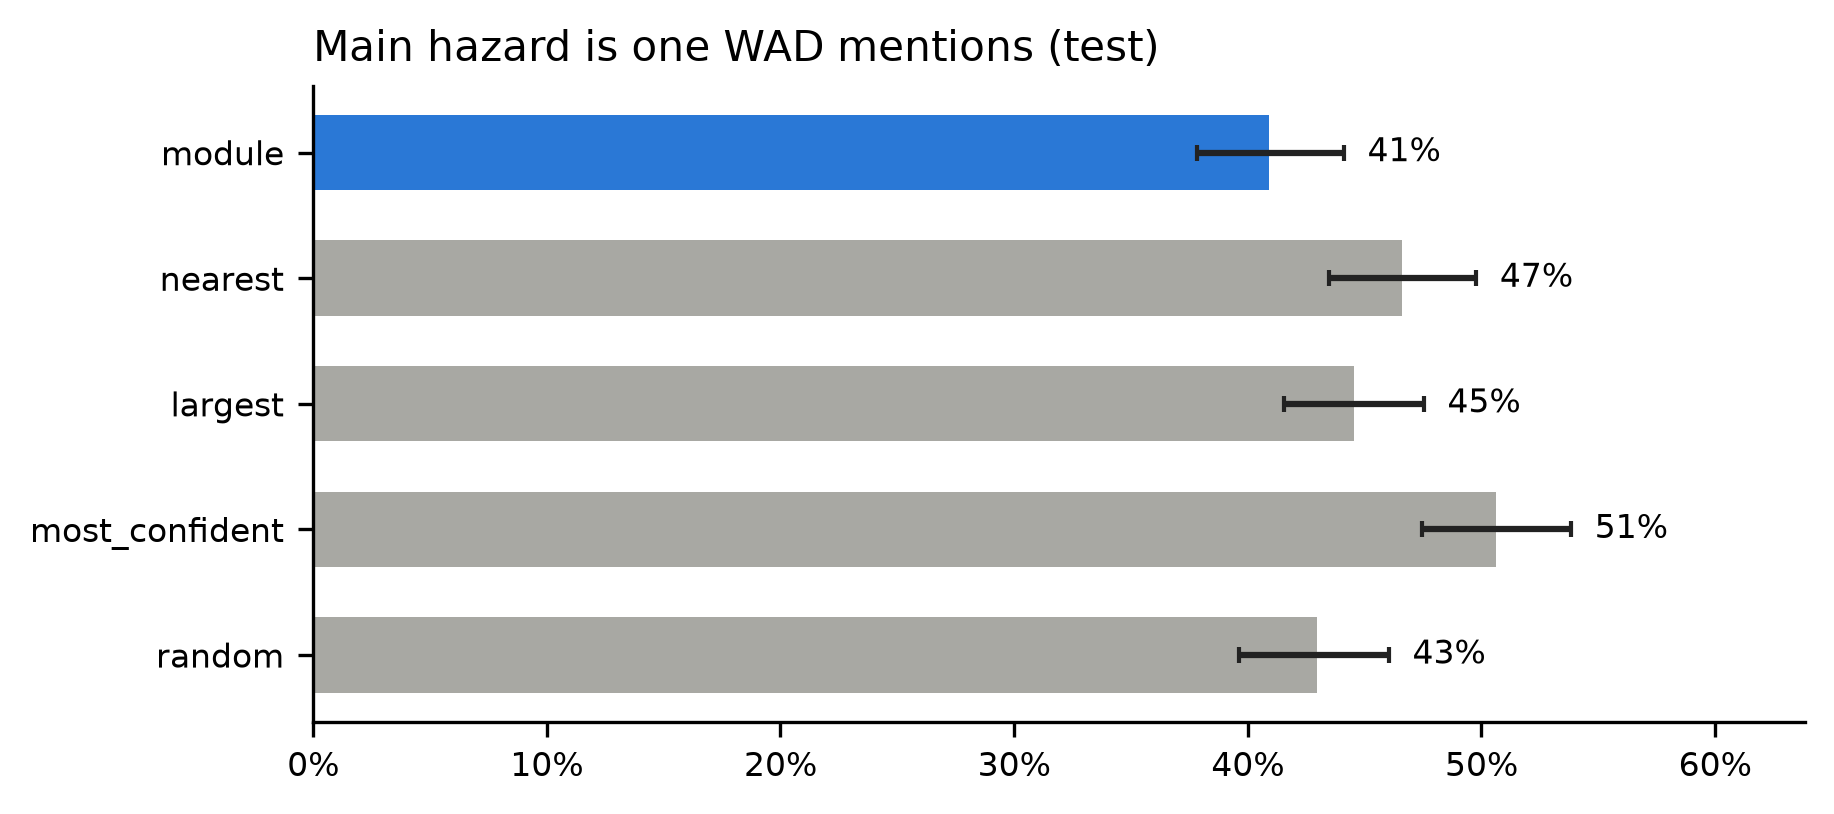

In [33]:
# figure: top-1 against WAD, module vs simple rules (bars = 95% intervals)
names = ["module", "nearest", "largest", "most_confident", "random"]
vals = [ci(per_clip(MODULE if n == "module" else baseline(n), WAD)["top-1"]) for n in names]
fig, ax = plt.subplots(figsize=(6, 2.6), layout="constrained")
ax.barh(names[::-1], [v[0] for v in vals[::-1]], color=[OTHER] * 4 + [OURS], height=0.6)
ax.errorbar([v[0] for v in vals[::-1]], names[::-1], xerr=np.array([[v[0] - v[1], v[2] - v[0]] for v in vals[::-1]]).T,
            fmt="none", ecolor=INK, capsize=2)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Main hazard is one WAD mentions (test)", loc="left", fontsize=10)
for y, v in enumerate(vals[::-1]):
    ax.text(v[2] + 0.01, y, f"{v[0]:.0%}", va="center", fontsize=8)
ax.set_xlim(0, max(v[2] for v in vals) + 0.1)
save_fig(fig, "hazard_vs_rules")
plt.show()

### 3.2. Action

In [34]:
def action_row(pred, ref):
    idx = pred.index.intersection(ref.index)
    y, p = ref.action.loc[idx], pred.action.loc[idx]
    return {"same action": "{:.0%} [{:.0%}, {:.0%}]".format(*ci((y == p).astype(float))),
            "macro-F1": round(f1_score(y, p, labels=ACTIONS, average="macro", zero_division=0), 2),
            "kappa": round(cohen_kappa_score(y, p, labels=ACTIONS), 2),
            "kappa (linear)": round(cohen_kappa_score(y, p, labels=ACTIONS, weights="linear"), 2),
            **{f"recall {a}": round(recall_score(y, p, labels=[a], average="macro", zero_division=0), 2) for a in ACTIONS}}

save_table(pd.DataFrame({"module vs WAD": action_row(MODULE, WAD), "module vs judges": action_row(MODULE, JUDGES),
                         "WAD vs judges": action_row(WAD, JUDGES)}).T, "action")

,same action,macro-F1,kappa,kappa (linear),recall continue,recall slow,recall move,recall stop
module vs WAD,"46% [43%, 49%]",0.26,0.05,0.05,0.53,0.44,0.14,0.0
module vs judges,"48% [43%, 53%]",0.35,0.22,0.22,0.77,0.49,0.17,0.06
WAD vs judges,"36% [31%, 41%]",0.22,0.05,0.07,0.83,0.16,0.1,0.0


### 3.3. Five levels of action
- A reference that says continue and names a hazard = caution; continue with nothing named = clear.
- "Caution correct" = of the clips the module marked caution, the share the reference also marks caution.

In [35]:
def level5(ref):
    named = ref.hazards.map(len) > 0
    return pd.Series(np.where(ref.action.ne("continue"), ref.action,
                              np.where(named, "caution", "clear")), index=ref.index)

rows = {}
for name, ref in [("module vs WAD", WAD), ("module vs judges", JUDGES)]:
    idx = MODULE.index.intersection(ref.index)
    p, r = MODULE.level.loc[idx], level5(ref.loc[idx])
    rows[name] = {"same level": f"{(p == r).mean():.0%}",
                  "kappa (5 levels)": round(cohen_kappa_score(r, p, labels=LEVELS), 2),
                  "caution correct": f"{(r[p == 'caution'] == 'caution').mean():.0%}",
                  "clear correct": f"{(r[p == 'clear'] == 'clear').mean():.0%}"}
save_table(pd.DataFrame(rows).T, "levels")

idx = MODULE.index.intersection(JUDGES.index)
pd.crosstab(level5(JUDGES.loc[idx]), MODULE.level.loc[idx], normalize="columns").round(2)

level,caution,clear,move,slow,stop
row_0,,,,,
caution,0.47,0.52,0.21,0.14,0.17
clear,0.05,0.07,0.00,0.01,0.00
move,0.06,0.07,0.24,0.16,0.17
slow,0.32,0.25,0.41,0.49,0.42
stop,0.11,0.09,0.14,0.20,0.25


### 3.4. Safety

In [36]:
def safety(pred, ref):
    idx = pred.index.intersection(ref.index)
    warns = ref.action.loc[idx].ne("continue")
    pa = pred.action.loc[idx].ne("continue")
    return {"silent when they warn": "{:.0%} [{:.0%}, {:.0%}]".format(*ci(pred.silent.loc[idx][warns].astype(float))),
            "over-warning when they say continue": f"{pa[~warns].mean():.0%}"}

save_table(pd.DataFrame({"module vs WAD": safety(MODULE, WAD), "module vs judges": safety(MODULE, JUDGES)}).T, "safety")

,silent when they warn,over-warning when they say continue
module vs WAD,"9% [6%, 13%]",47%
module vs judges,"8% [4%, 11%]",23%


## 4. Ablation and subsets

### 4.1. Ablations

In [37]:
ABLATIONS = ["full", "no_severity", "no_closeness", "no_position", "no_motion", "objects_only"]
PC = {v: per_clip(module(variant=v), WAD) for v in ABLATIONS}
abl = pd.DataFrame({v: {**summary(PC[v], ["top-1", "top-3", "silent"]),
                        "top-1 vs full": mcnemar(PC[v]["top-1"], PC["full"]["top-1"]) if v != "full" else "",
                        "silent vs full": mcnemar(PC[v]["silent"], PC["full"]["silent"]) if v != "full" else ""}
                    for v in ABLATIONS}).T
save_table(abl, "ablations")

,top-1,top-3,silent,top-1 vs full,silent vs full
full,"41% [38%, 44%]","61% [57%, 64%]","9% [6%, 13%]",,
no_severity,"47% [44%, 51%]","62% [58%, 65%]","9% [6%, 13%]","84 / 24, p = 0.000","0 / 0, p = 1.000"
no_closeness,"42% [39%, 45%]","59% [56%, 62%]","9% [6%, 13%]","46 / 36, p = 0.320","0 / 0, p = 1.000"
no_position,"38% [35%, 41%]","59% [56%, 62%]","9% [6%, 13%]","27 / 54, p = 0.004","0 / 0, p = 1.000"
no_motion,"38% [35%, 42%]","59% [56%, 62%]","9% [6%, 13%]","11 / 35, p = 0.001","0 / 0, p = 1.000"
objects_only,"46% [43%, 49%]","58% [55%, 62%]","22% [17%, 27%]","76 / 25, p = 0.000","34 / 0, p = 0.000"


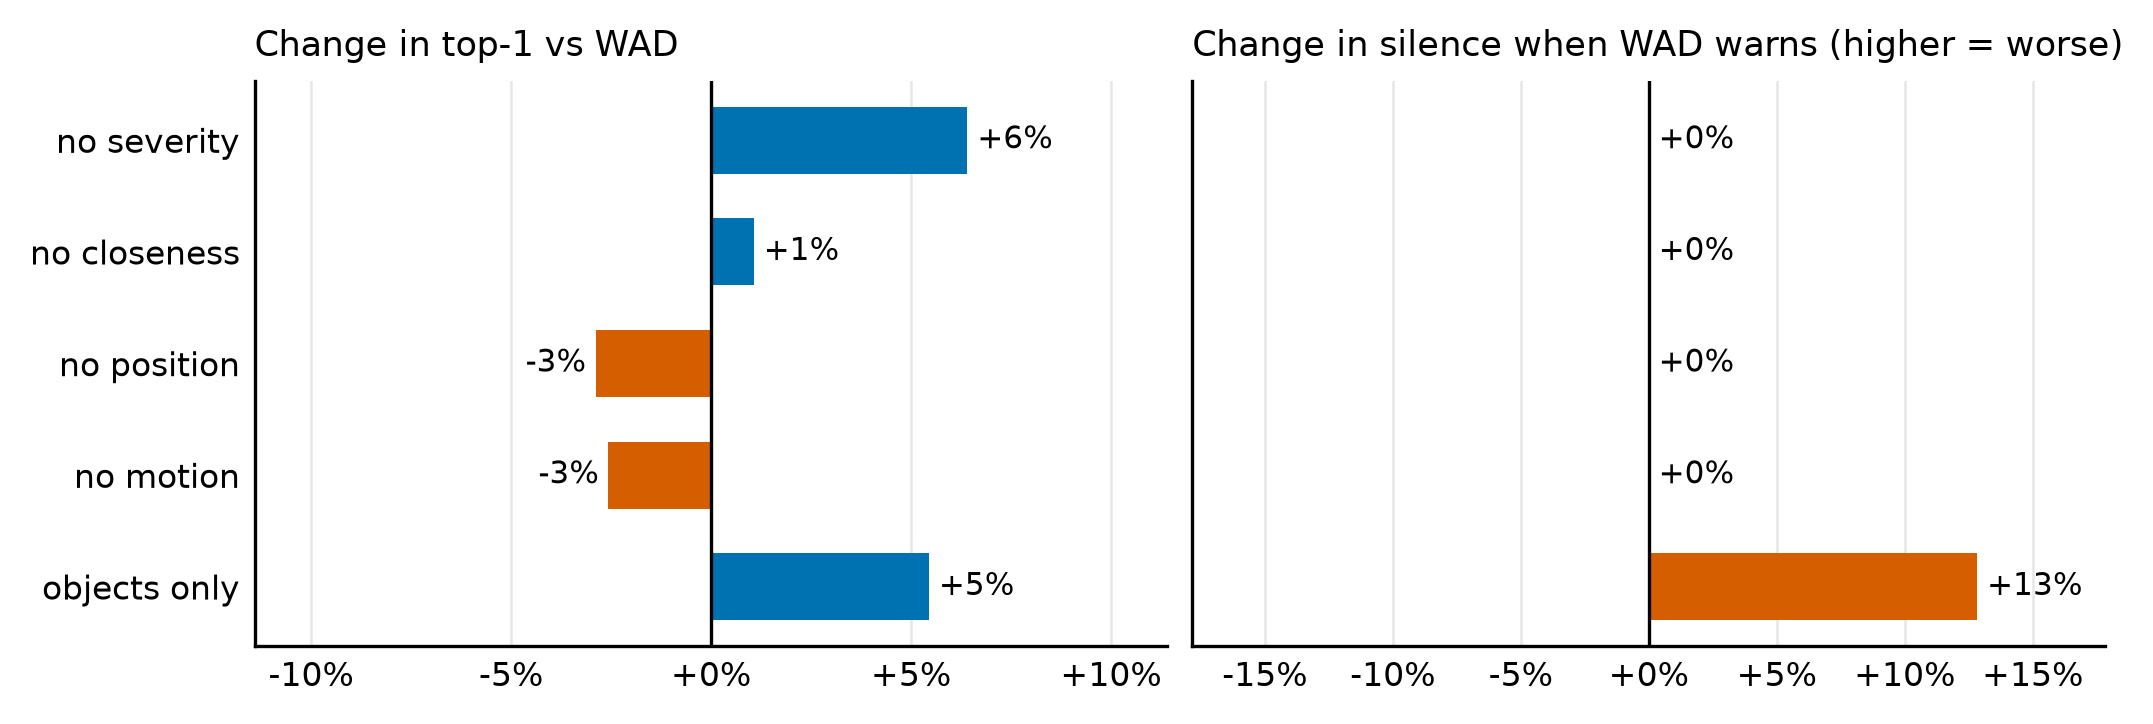

In [38]:
NICE = {"no_severity": "no severity", "no_closeness": "no closeness", "no_position": "no position",
        "no_motion": "no motion", "objects_only": "objects only"}
names = ABLATIONS[1:]
labels = [NICE[v] for v in names][::-1]
panels = [("Change in top-1 vs WAD", "top-1", False), ("Change in silence when WAD warns (higher = worse)", "silent", True)]

fig, axs = plt.subplots(1, 2, figsize=(7.0, 2.3), layout="constrained", sharey=True)
for ax, (title, m, higher_worse) in zip(axs, panels):
    vals = [PC[v][m].mean() - PC["full"][m].mean() for v in names][::-1]
    cols = [(ORANGE if v > 0 else BLUE) if higher_worse else (BLUE if v > 0 else ORANGE) for v in vals]
    ax.barh(labels, vals, color=cols, height=0.6)
    ax.axvline(0, color="black", lw=0.8)
    ax.grid(axis="x", color="#E5E7EB", lw=0.6); ax.set_axisbelow(True)
    for y, v in enumerate(vals):
        ax.text(v, y, f" {v:+.0%} ", va="center", ha="left" if v >= 0 else "right", fontsize=7.5)
    lim = max(abs(min(vals + [0])), abs(max(vals + [0]))) + 0.05
    ax.set_xlim(-lim, lim)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
    ax.tick_params(length=0)
    ax.set_title(title, fontsize=8.5, loc="left")
save_fig(fig, "ablations")
plt.show()

In [39]:
VAR = {v: module(variant=v) for v in ABLATIONS}
PCJ = {v: per_clip(VAR[v], JUDGES) for v in ABLATIONS}
ablj = pd.DataFrame({v: {**summary(PCJ[v], ["top-1", "action", "silent"]),
                          "action kappa": f"{kappa(VAR[v], JUDGES):.2f}",
                          "top-1 vs full": mcnemar(PCJ[v]["top-1"], PCJ["full"]["top-1"]) if v != "full" else ""}
                     for v in ABLATIONS}).T
save_table(ablj, "ablations_judges")
ablj

,top-1,action,silent,action kappa,top-1 vs full
full,"44% [39%, 49%]","48% [43%, 53%]","8% [4%, 11%]",0.22,
no_severity,"53% [48%, 58%]","48% [43%, 53%]","8% [4%, 11%]",0.22,"36 / 7, p = 0.000"
no_closeness,"42% [36%, 47%]","48% [43%, 53%]","8% [4%, 11%]",0.22,"10 / 19, p = 0.136"
no_position,"39% [34%, 44%]","48% [43%, 53%]","8% [4%, 11%]",0.22,"9 / 26, p = 0.006"
no_motion,"39% [34%, 44%]","42% [37%, 47%]","8% [4%, 11%]",0.13,"1 / 20, p = 0.000"
objects_only,"46% [41%, 51%]","50% [44%, 55%]","17% [12%, 21%]",0.23,"25 / 19, p = 0.451"


### 4.2. Results per subset

In [40]:
done = [s for s in SUBSETS if (OUT / s / "hints.jsonl").exists()]
subsets = pd.DataFrame({s: {"clips": len(wad(s)), **summary(per_clip(module(s), wad(s)), ["top-1", "top-3", "direction", "action", "silent"]),
                            "action kappa": f"{kappa(module(s), wad(s)):.2f}"} for s in done}).T
save_table(subsets, "subsets")

,clips,top-1,top-3,direction,action,silent,action kappa
dev_00,500,"41% [37%, 46%]","60% [56%, 64%]","90% [86%, 94%]","47% [43%, 52%]","6% [2%, 10%]",0.05
check_01,500,"45% [40%, 49%]","62% [57%, 66%]","85% [80%, 90%]","51% [46%, 55%]","13% [7%, 19%]",0.08
check_02,500,"45% [40%, 49%]","65% [60%, 69%]","90% [85%, 94%]","43% [38%, 47%]","8% [4%, 13%]",0.04
check_03,500,"41% [37%, 46%]","58% [54%, 63%]","90% [86%, 94%]","48% [44%, 53%]","8% [4%, 13%]",0.10
check_04,500,"37% [33%, 41%]","56% [52%, 61%]","92% [88%, 96%]","46% [41%, 50%]","6% [2%, 10%]",0.06
test,1007,"41% [38%, 44%]","61% [57%, 64%]","88% [84%, 91%]","46% [43%, 49%]","9% [6%, 13%]",0.05


## 5. Qwen-VL-2B with and without the hint

### 5.1. Hazard, direction, action and silence

In [41]:
SOURCES = {"Qwen, no hint": QW["none"], "Qwen, object list": QW["list"], "Qwen, ranked hint": QW["ranked"], "module alone (no Qwen)": MODULE}
content = {}
for ref_name, ref in [("WAD", WAD), ("judges", JUDGES)]:
    for name, src in SOURCES.items():
        content[f"{name} vs {ref_name}"] = {**summary(per_clip(src, ref), ["top-1", "direction", "action", "silent"]),
                                            "action kappa": f"{kappa(src, ref):.2f}"}
save_table(pd.DataFrame(content).T, "qwen_content")

,top-1,direction,action,silent,action kappa
"Qwen, no hint vs WAD","19% [17%, 22%]","22% [0%, 56%]","42% [39%, 45%]","33% [28%, 38%]",-0.00
"Qwen, object list vs WAD","43% [40%, 46%]","82% [78%, 86%]","63% [60%, 66%]","1% [0%, 2%]",0.05
"Qwen, ranked hint vs WAD","44% [41%, 47%]","87% [84%, 91%]","45% [42%, 48%]","9% [6%, 13%]",0.05
module alone (no Qwen) vs WAD,"41% [38%, 44%]","88% [84%, 91%]","46% [43%, 49%]","9% [6%, 13%]",0.05
"Qwen, no hint vs judges","14% [10%, 18%]","25% [0%, 75%]","28% [23%, 33%]","41% [35%, 48%]",-0.03
"Qwen, object list vs judges","43% [38%, 49%]","92% [87%, 96%]","29% [24%, 34%]","0% [0%, 0%]",-0.04
"Qwen, ranked hint vs judges","43% [38%, 48%]","98% [95%, 100%]","47% [42%, 53%]","8% [4%, 11%]",0.22
module alone (no Qwen) vs judges,"44% [39%, 49%]","98% [95%, 100%]","48% [43%, 53%]","8% [4%, 11%]",0.22


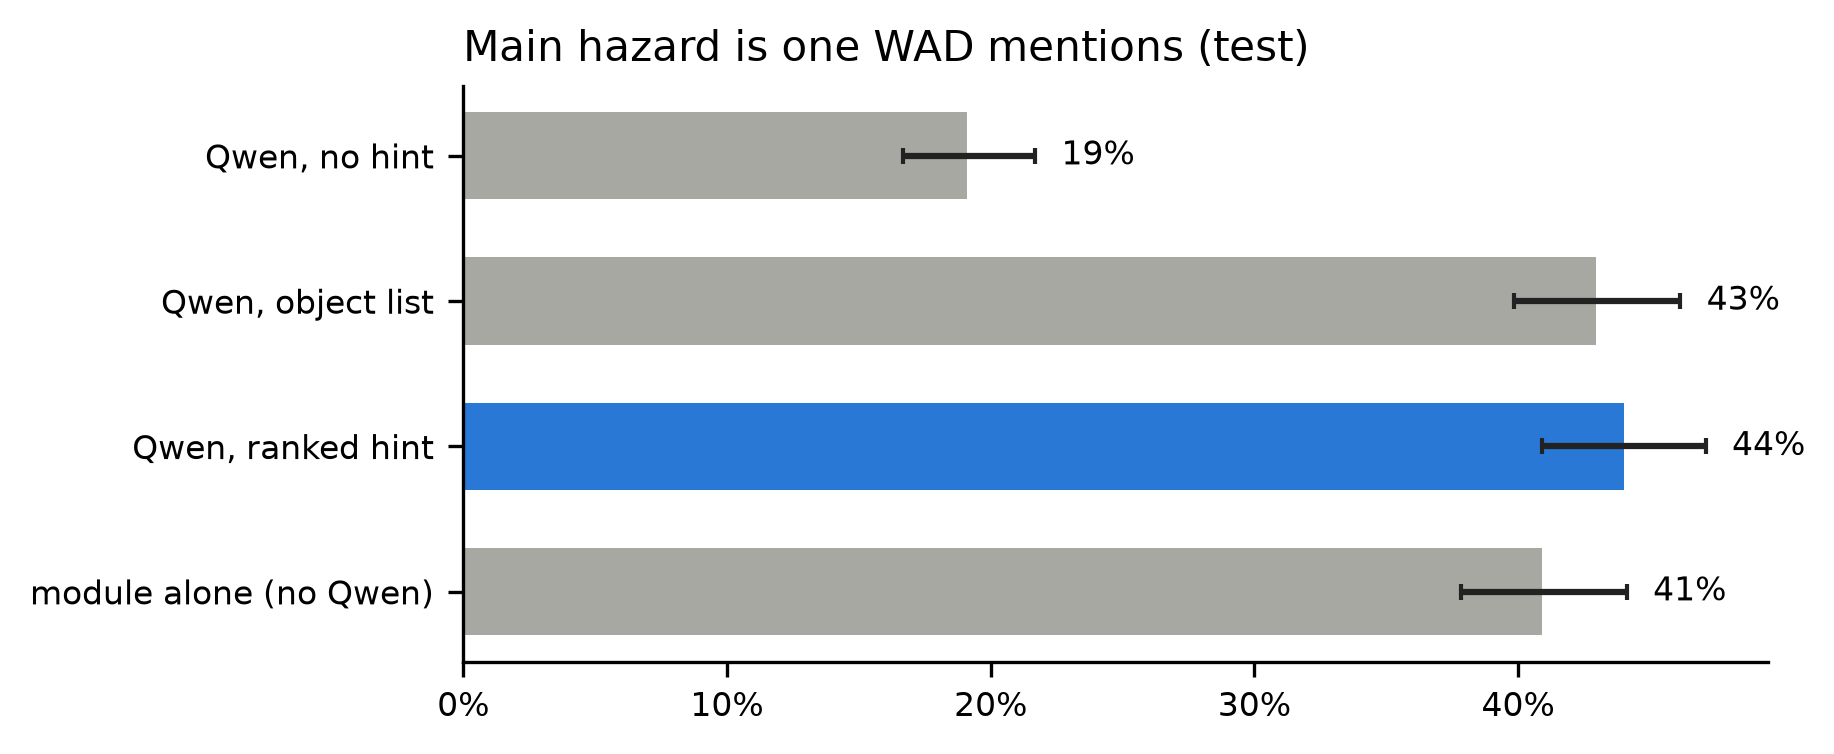

In [42]:
# figure: main hazard matches WAD, per condition
names = ["Qwen, no hint", "Qwen, object list", "Qwen, ranked hint", "module alone (no Qwen)"]
vals = [ci(per_clip(SOURCES[n], WAD)["top-1"]) for n in names]
fig, ax = plt.subplots(figsize=(6, 2.4), layout="constrained")
ax.barh(names[::-1], [v[0] for v in vals[::-1]], color=[OTHER, OURS, OTHER, OTHER], height=0.6)
ax.errorbar([v[0] for v in vals[::-1]], names[::-1], xerr=np.array([[v[0] - v[1], v[2] - v[0]] for v in vals[::-1]]).T,
            fmt="none", ecolor=INK, capsize=2)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Main hazard is one WAD mentions (test)", loc="left", fontsize=10)
for y, v in enumerate(vals[::-1]):
    ax.text(v[2] + 0.01, y, f"{v[0]:.0%}", va="center", fontsize=8)
save_fig(fig, "qwen_top1")
plt.show()

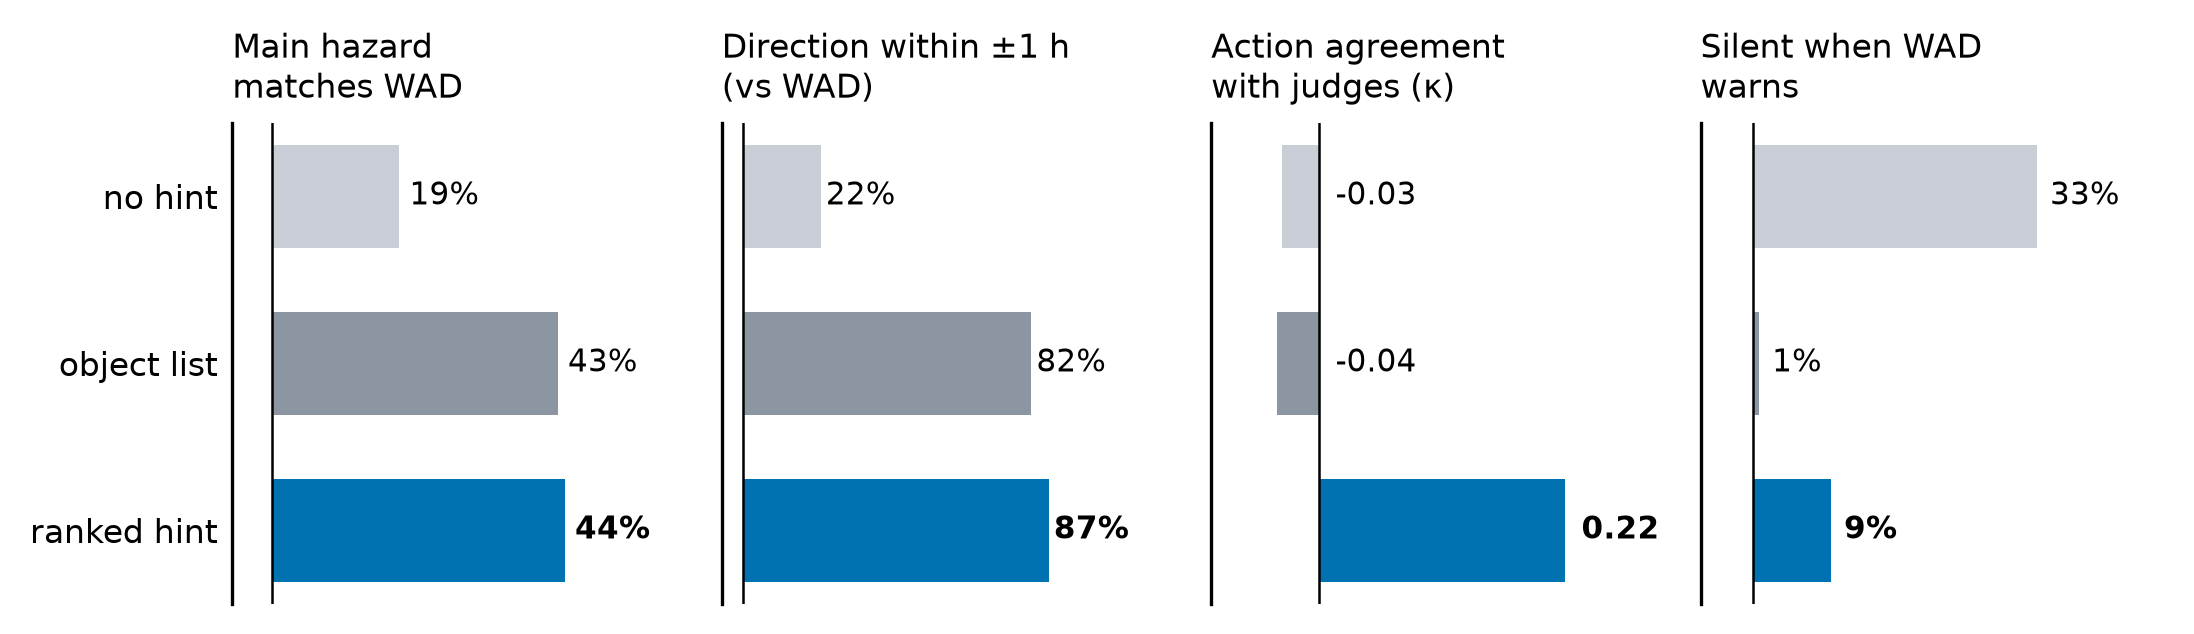

In [43]:
conds = {"no hint": QW["none"], "object list": QW["list"], "ranked hint": QW["ranked"]}
colors = [BLUE, GREY_D, GREY_L]                     # ranked, list, none (bottom to top after reversing)
panels = [("Main hazard\nmatches WAD", lambda s: per_clip(s, WAD)["top-1"].mean(), "{:.0%}"),
          ("Direction within ±1 h\n(vs WAD)", lambda s: per_clip(s, WAD)["direction"].mean(), "{:.0%}"),
          ("Action agreement\nwith judges (κ)", lambda s: kappa(s, JUDGES), "{:.2f}"),
          ("Silent when WAD\nwarns", lambda s: per_clip(s, WAD)["silent"].mean(), "{:.0%}")]

fig, axs = plt.subplots(1, 4, figsize=(7.2, 2.0), layout="constrained", sharey=True)
for ax, (title, f, fmt) in zip(axs, panels):
    vals = [f(s) for s in conds.values()][::-1]
    ax.barh(list(conds)[::-1], vals, color=colors, height=0.62)
    ax.axvline(0, color="black", lw=0.6)
    for y, v in enumerate(vals):
        ax.text(max(v, 0) + 0.015, y, fmt.format(v), va="center", fontsize=7.5,
                fontweight="bold" if y == 0 else "normal")
    ax.set_xlim(min(vals + [0]) - 0.06, max(vals) * 1.45)
    ax.set_xticks([]); ax.tick_params(length=0)
    ax.spines["bottom"].set_visible(False)
    ax.set_title(title, fontsize=8, loc="left")
save_fig(fig, "qwen_conditions")
plt.show()

### 5.2. Paired tests (McNemar)

In [44]:
tests = {}
for a, b in [("ranked", "none"), ("ranked", "list"), ("list", "none")]:
    pa, pb = per_clip(QW[a], WAD), per_clip(QW[b], WAD)
    tests[f"{a} vs {b}"] = {m: mcnemar(pa[m], pb[m]) for m in ["top-1", "direction", "action", "silent"]}
save_table(pd.DataFrame(tests).T, "qwen_tests")

,top-1,direction,action,silent
ranked vs none,"302 / 69, p = 0.000","4 / 0, p = 0.125","267 / 230, p = 0.106","19 / 82, p = 0.000"
ranked vs list,"136 / 126, p = 0.578","26 / 12, p = 0.034","136 / 319, p = 0.000","24 / 2, p = 0.000"
list vs none,"288 / 65, p = 0.000","5 / 0, p = 0.062","311 / 91, p = 0.000","0 / 85, p = 0.000"


### 5.3. Wording vs the human reminders, and WalkVLM
- ROUGE-1/2/L (standard `rouge-score` package, with stemming), TF-IDF and MiniLM similarity between each reply and WAD's reminder.
- WalkVLM numbers are from its ICCV 2025 paper (Table 3). Its TF-IDF settings are not reported, so TF-IDF is also shown under four common settings.

In [45]:
from rouge_score import rouge_scorer
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

ann = pd.concat([pd.read_json(WAD_ROOT / f, lines=True) for f in ["train_v2.json", "test_alter_v2.json"]])
ref_text = ann.drop_duplicates("frame_path").set_index("frame_path")["alter"].reindex(QWEN.index).fillna("")
texts = {c: QWEN[f"qwen_{c}"].astype(str) for c in ["none", "list", "ranked"]}
all_text = pd.concat([ref_text, *texts.values()])

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
ref_emb = st.encode(ref_text.tolist(), normalize_embeddings=True)

TFIDF = {"all texts": TfidfVectorizer().fit(all_text),
         "references only": TfidfVectorizer().fit(ref_text),
         "no stop words": TfidfVectorizer(stop_words="english").fit(all_text),
         "1-2 grams": TfidfVectorizer(ngram_range=(1, 2)).fit(all_text)}

def tfidf_sim(vec, t):
    return np.asarray(vec.transform(t).multiply(vec.transform(ref_text)).sum(1)).mean()

wording, tfidf_settings = {}, {}
for c, t in texts.items():
    s = [scorer.score(r, h) for r, h in zip(ref_text, t)]
    wording[f"Qwen2-VL-2B, {c} (ours, no training)"] = {
        "TF-IDF": tfidf_sim(TFIDF["all texts"], t),
        "ROUGE-1": np.mean([x["rouge1"].fmeasure for x in s]),
        "ROUGE-2": np.mean([x["rouge2"].fmeasure for x in s]),
        "ROUGE-L": np.mean([x["rougeL"].fmeasure for x in s]),
        "MiniLM": (st.encode(t.tolist(), normalize_embeddings=True) * ref_emb).sum(1).mean()}
    tfidf_settings[f"Qwen2-VL-2B, {c}"] = {name: tfidf_sim(vec, t) for name, vec in TFIDF.items()}

# WalkVLM, ICCV 2025, Table 3 (reminder task): check against the published PDF before reporting
WALKVLM = {"GPT-4o (no training)":            (0.116, 0.078, 0.008, 0.072),
           "Qwen2-VL-7B (no training)":       (0.106, 0.107, 0.010, 0.097),
           "Qwen2-VL-7B (fine-tuned on WAD)": (0.147, 0.163, 0.054, 0.165),
           "WalkVLM (fine-tuned on WAD)":     (0.166, 0.191, 0.062, 0.173)}
for name, v in WALKVLM.items():
    wording[f"{name} [WalkVLM paper]"] = dict(zip(["TF-IDF", "ROUGE-1", "ROUGE-2", "ROUGE-L"], v))

save_table(pd.DataFrame(wording).T.round(3), "wording")
save_table(pd.DataFrame(tfidf_settings).T.round(3), "wording_tfidf_settings")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6621.20it/s]


,all texts,references only,no stop words,1-2 grams
"Qwen2-VL-2B, none",0.073,0.093,0.050,0.031
"Qwen2-VL-2B, list",0.100,0.112,0.077,0.046
"Qwen2-VL-2B, ranked",0.102,0.098,0.086,0.044


### 5.4. Reply length
- Mean, median and SD of words per reply (whitespace split), for each condition and for WAD's reminders.

In [52]:
def n_words(s):
    return s.fillna("").astype(str).str.split().str.len()
 
lengths = {c: n_words(t) for c, t in texts.items()}   # none / list / ranked
lengths["WAD"] = n_words(ref_text)
length_table = pd.DataFrame({k: {"mean": v.mean(), "median": v.median(), "sd": v.std()}
                             for k, v in lengths.items()}).T.round(1)
save_table(length_table, "reply_length")
print(length_table)

        mean  median    sd
none    42.1    49.0  25.1
list    23.5    21.0  10.0
ranked  27.9    24.0  13.2
WAD     15.2    14.0   6.1


### 5.5. Uncertainty in Cohen's $\kappa$
- 95% percentile bootstrap intervals (2,000 resamples of clips, seed 42) for every κ in the report, including the module and WAD from Section 3.
- An interval that includes 0 means the agreement cannot be distinguished from chance.

In [47]:
def _aligned(pred, ref):
    idx = pred.index.intersection(ref.index)
    y, p = ref.action.loc[idx].to_numpy(), pred.action.loc[idx].to_numpy()
    ok = pd.notna(y) & pd.notna(p)
    return y[ok], p[ok]
 
def kappa_ci(pred, ref, n_boot=N_BOOT, seed=SEED):
    y, p = _aligned(pred, ref)
    rng = np.random.default_rng(seed)
    boot = [cohen_kappa_score(y[i], p[i], labels=ACTIONS)
            for i in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))]
    return cohen_kappa_score(y, p, labels=ACTIONS), *np.nanpercentile(boot, [2.5, 97.5])
 
def fmt_k(t):
    return f"{t[0]:.2f} [{t[1]:.2f}, {t[2]:.2f}]"
 
kappa_rows = {
    "judge 1 vs judge 2 (50 shared)": kappa_ci(J1, J2),
    "WAD vs judges (350)":            kappa_ci(WAD, JUDGES),
    "module vs judges (350)":         kappa_ci(MODULE, JUDGES),
    "module vs WAD (1,007)":          kappa_ci(MODULE, WAD),
    "Qwen no hint vs judges":         kappa_ci(QW["none"], JUDGES),
    "Qwen object list vs judges":     kappa_ci(QW["list"], JUDGES),
    "Qwen ranked hint vs judges":     kappa_ci(QW["ranked"], JUDGES),
    "Qwen no hint vs WAD":            kappa_ci(QW["none"], WAD),
    "Qwen object list vs WAD":        kappa_ci(QW["list"], WAD),
    "Qwen ranked hint vs WAD":        kappa_ci(QW["ranked"], WAD),
}
kappa_table = pd.Series({k: fmt_k(v) for k, v in kappa_rows.items()}, name="kappa [95% CI]")
save_table(kappa_table.to_frame(), "kappa_ci")
print(kappa_table)
print("\nCI includes 0 (= not distinguishable from chance):")
for k, (_, lo_, hi_) in kappa_rows.items():
    print(f"  {k:32s} {'YES' if lo_ <= 0 <= hi_ else 'no'}")


judge 1 vs judge 2 (50 shared)      0.85 [0.72, 0.97]
WAD vs judges (350)                0.05 [-0.00, 0.10]
module vs judges (350)              0.22 [0.15, 0.29]
module vs WAD (1,007)               0.05 [0.01, 0.09]
Qwen no hint vs judges            -0.03 [-0.09, 0.03]
Qwen object list vs judges        -0.04 [-0.08, 0.00]
Qwen ranked hint vs judges          0.22 [0.15, 0.29]
Qwen no hint vs WAD               -0.00 [-0.03, 0.03]
Qwen object list vs WAD             0.05 [0.01, 0.09]
Qwen ranked hint vs WAD             0.05 [0.01, 0.09]
Name: kappa [95% CI], dtype: str

CI includes 0 (= not distinguishable from chance):
  judge 1 vs judge 2 (50 shared)   no
  WAD vs judges (350)              YES
  module vs judges (350)           no
  module vs WAD (1,007)            no
  Qwen no hint vs judges           YES
  Qwen object list vs judges       YES
  Qwen ranked hint vs judges       no
  Qwen no hint vs WAD              YES
  Qwen object list vs WAD          no
  Qwen ranked hint vs WAD    

### 5.6. Paired $\kappa$ differences
- Resamples the same clips for both systems, so the difference is tested on matched data.
- Two-sided bootstrap p-value: twice the share of resamples on the wrong side of 0.
- Tests the claims that the module beats WAD, and the ranked hint beats the list, on agreement with the judges.

In [48]:
def kappa_diff(a, b, ref, n_boot=N_BOOT, seed=SEED):
    idx = a.index.intersection(b.index).intersection(ref.index)
    y, pa, pb = (ref.action.loc[idx].to_numpy(), a.action.loc[idx].to_numpy(), b.action.loc[idx].to_numpy())
    k = lambda i: cohen_kappa_score(y[i], pa[i], labels=ACTIONS) - cohen_kappa_score(y[i], pb[i], labels=ACTIONS)
    rng = np.random.default_rng(seed)
    d = np.array([k(rng.integers(0, len(y), len(y))) for _ in range(n_boot)])
    obs = k(np.arange(len(y)))
    p = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))   # two-sided bootstrap p
    return f"{obs:+.2f} [{np.nanpercentile(d, 2.5):+.2f}, {np.nanpercentile(d, 97.5):+.2f}], p = {p:.3f}"
 
diffs = pd.Series({
    "module - WAD (vs judges)":        kappa_diff(MODULE, WAD, JUDGES),
    "ranked - list (vs judges)":       kappa_diff(QW["ranked"], QW["list"], JUDGES),
    "ranked - none (vs judges)":       kappa_diff(QW["ranked"], QW["none"], JUDGES),
}, name="kappa difference [95% CI], p")
save_table(diffs.to_frame(), "kappa_differences")
print(diffs)


module - WAD (vs judges)     +0.17 [+0.09, +0.26], p = 0.000
ranked - list (vs judges)    +0.26 [+0.18, +0.34], p = 0.000
ranked - none (vs judges)    +0.26 [+0.16, +0.36], p = 0.000
Name: kappa difference [95% CI], p, dtype: str


### 5.7. Paired tests against the judges
- Same McNemar tests as 5.2, but against the 350 judged clips. Cells give clips where only the first / only the second condition is correct (for silence: is silent).
- Reported in Appendix H alongside the tests against WAD.

In [49]:
tests_j = {}
for a, b in [("ranked", "none"), ("ranked", "list"), ("list", "none")]:
    pa, pb = per_clip(QW[a], JUDGES), per_clip(QW[b], JUDGES)
    tests_j[f"{a} vs {b}"] = {m: mcnemar(pa[m], pb[m]) for m in ["top-1", "direction", "action", "silent"]}
save_table(pd.DataFrame(tests_j).T, "qwen_tests_judges")
pd.DataFrame(tests_j).T

,top-1,direction,action,silent
ranked vs none,"123 / 23, p = 0.000","1 / 0, p = 1.000","116 / 49, p = 0.000","9 / 86, p = 0.000"
ranked vs list,"49 / 48, p = 1.000","2 / 1, p = 1.000","91 / 27, p = 0.000","18 / 0, p = 0.000"
list vs none,"115 / 16, p = 0.000","3 / 0, p = 0.250","54 / 51, p = 0.845","0 / 95, p = 0.000"


## 6. Qualitative examples

In [50]:
# judged test clips meeting each criterion, in a fixed random order
idx = JUDGES.index.intersection(WAD.index).to_series().sample(frac=1, random_state=SEED).index
mj, mw = per_clip(MODULE, JUDGES).loc[idx], per_clip(MODULE, WAD).loc[idx]
rj, nj = per_clip(QW["ranked"], JUDGES).loc[idx], per_clip(QW["none"], JUDGES).loc[idx]
both_warn = JUDGES.action.loc[idx].ne("continue") & WAD.action.loc[idx].ne("continue")
crit = {"a: ranked hint fixes the no-hint reply": (rj["top-1"] == 1) & (rj["action"] == 1) & (nj["top-1"] == 0),
        "b: module agrees with judges, not WAD": (mj["top-1"] == 1) & (mw["top-1"] == 0),
        "c: module clear, both references warn": MODULE.level.loc[idx].eq("clear") & both_warn}

for name, mask in crit.items():
    print(f"\n===== {name}: {mask.sum()} clips =====")
    for clip in mask[mask].index[:3]:
        print(clip)
        print("  module :", MODULE.loc[clip, "level"], "|", HINT[clip])
        for c in ["none", "list", "ranked"]:
            print(f"  {c:7}:", QWEN.loc[clip, f"qwen_{c}"])
        print("  WAD    :", WAD.loc[clip, ["top", "clock", "action"]].tolist())
        print("  judges :", JUDGES.loc[clip, ["top", "clock", "action"]].tolist())


===== a: ranked hint fixes the no-hint reply: 63 clips =====
20240918-youtube_short_b47bfc6eff24bcacbc44e6f85504989b_1m7s.frame
  module : caution | 1) person | 12 o'clock | 12 steps | further ahead | same direction
2) motorcycle | 1 o'clock | 10 steps | beside your path | same direction
3) person | 12 o'clock | 11 steps | in your path | same direction
Action: keep going, be careful.
Context: on the road.
  none   : The path ahead is clear. Keep going.
  list   : The hazard is a motorcycle at 1 o'clock, about 10 steps away. You should turn left.
  ranked : The hazard ahead of them is a person at 12 o'clock, walking the same way as you. They are 11 steps away. Your next action is to watch out for the motorcycle at 1 o'clock, walking the same way as you. The motorcycle is 10 steps away. Your next action is to be careful.
  WAD    : ['pedestrian', np.float64(2.0), 'continue']
  judges : ['pedestrian', np.float64(1.0), 'continue']
20240918-youtube_short_8a948f34e08caf8d442db86b90598719_4m

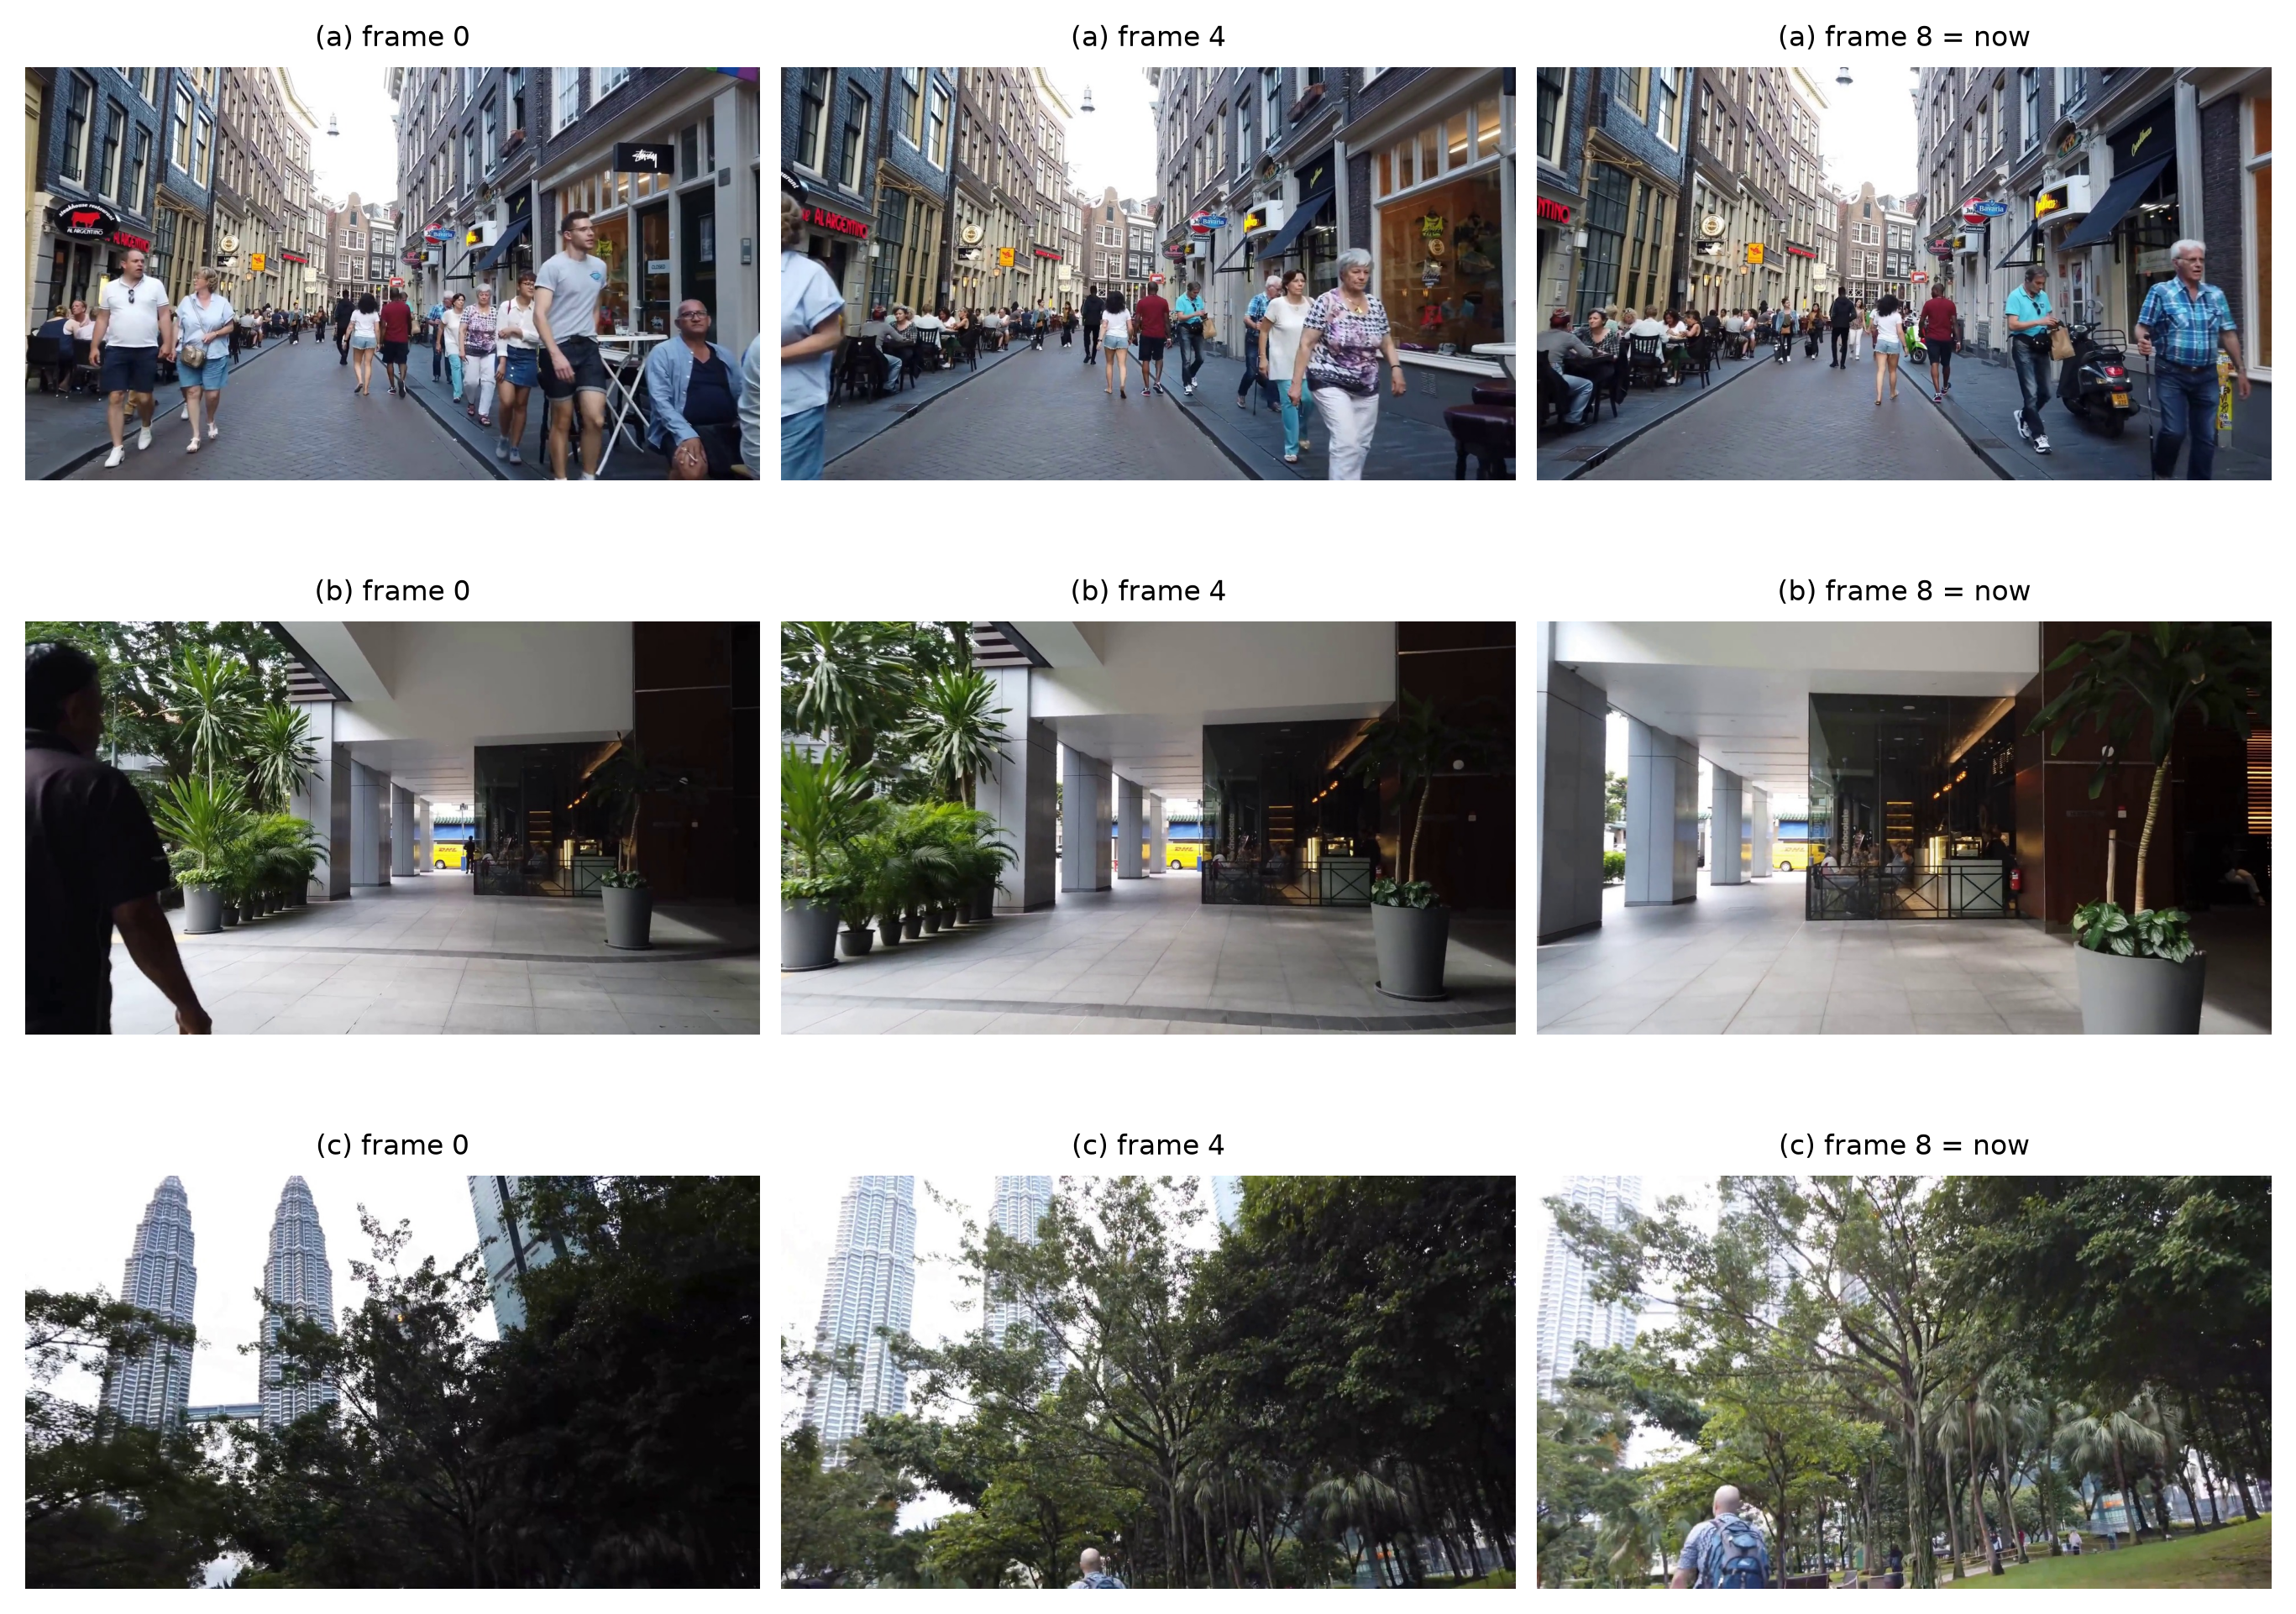

In [51]:
# three qualitative examples
from PIL import Image

EXAMPLES = {"a": "20240918-youtube_short_b47bfc6eff24bcacbc44e6f85504989b_1m7s.frame",
            "b": "20240918-youtube_short_cc8241e21f273fd213a4e857bb320f77_4min19s.frame",
            "c": "20240918-youtube_short_93d2c485fdb77d26f4e13e339c2effa4_2min52s.frame"}
SHOW = [0, 4, 8]                     # use range(9) to see every frame

fig, axes = plt.subplots(len(EXAMPLES), len(SHOW), figsize=(3 * len(SHOW), 2.2 * len(EXAMPLES)), layout="constrained")
for row, (name, clip) in zip(axes, EXAMPLES.items()):
    folder = next((REPO_ROOT / "data").rglob(clip))
    for ax, k in zip(row, SHOW):
        ax.imshow(Image.open(folder / f"{k}.jpg"))
        ax.set_title(f"({name}) frame {k}" + (" = now" if k == 8 else ""), fontsize=8)
        ax.axis("off")
plt.show()